# 04 · Model rankings

Which models are consistently near the top, which are good at some things but not others, and which are consistently weak?

Every model is ranked inside each cell of track × target × horizon × error metric (1 = best, ties averaged), and the ranks are then averaged along each dimension. Ranks are scale-free, so cells for different targets and metrics can be averaged directly.

- Metrics: RMSE, MAE, median AE and MASE. RMSPE is left out because it divides by growth rates near zero.
- Each fold has a 1-month test window, so per-fold `mae` is the absolute error of that month. Pooled over folds: RMSE = sqrt(mean `mse`), MAE = mean `mae`, median AE = median `mae`, MASE = mean `mase`. (Averaging the per-fold `rmse` column would just give MAE again.)
- Within each cell only folds that every ranked model has are used, so all models are scored on the same test months.

Sections

1. Coverage
2. Main ranking: every model on `MAIN_TRACK`
3. Recessions, expansions and COVID
4. Model profiles
5. Configurations: model@track across all tracks

Reads `results/raw/` only. Figures go to `results/figures/rank_*.png`, tables to `results/tables/rank_*.csv`.

In [1]:
# ---- Models and tracks ----
MODEL_LIST = ["random_walk", "AR6", "arima", "linear_readout",                 # benchmarks
              "decision_tree", "adaboost", "random_forest", "xgboost",         # tree-based
              "linear_svm", "sig_kernel"]                                      # kernel-based
MAIN_TRACK = "B"                              # main ranking: every model on this one track
QUANTUM_TRACKS = ["Q_su_pce", "Q_su_pauli", "Q_su_bitstring", "Q_su_single_bit", "Q_heisenberg_pce"]
FEATURELESS = ["random_walk", "AR6", "arima"]  # ignore the features, so they score the same on every track

# ---- Ranking ----
METRICS = ["rmse", "mae", "median_ae", "mase"]
TOP_K = 3              # "top-k share" column in the leaderboard
# profile thresholds, as a share of the rank range (n - 1), so they scale with the number of entries
METRIC_SHIFT = 0.2     # rank gap between RMSE and MAE/median AE that counts as metric-sensitive (1.8 places of 10)
REGIME_SHIFT = 0.3     # rank change from expansion to a crisis regime that counts as a regime specialist (2.7 places of 10)

# ---- Regimes ----
COVID_WINDOW = ("2020-03-01", "2021-06-01")   # test months tagged COVID instead of recession/expansion

RESULTS_DIR = None                            # None = <repo>/results

## Setup

In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

if "google.colab" in sys.modules:  # repo cloned by 02_evaluation_loop's setup cell
    REPO_ROOT = Path("/content/capstone-quantum")
    sys.path.insert(0, str(REPO_ROOT))
else:
    REPO_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())

from src.evaluation import load_results

DATA_DIR    = REPO_ROOT / "data" / "processed"
RESULTS_DIR = Path(RESULTS_DIR) if RESULTS_DIR else REPO_ROOT / "results"
FIG_DIR     = RESULTS_DIR / "figures"
TABLE_DIR   = RESULTS_DIR / "tables"
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)

raw = load_results(RESULTS_DIR, models=MODEL_LIST)
ok  = raw[raw["error"].isna()].copy()
usrec = pd.read_parquet(DATA_DIR / "usrec.parquet").iloc[:, 0].rename("usrec")

# regime of each fold's test month: COVID overrides the NBER flag
REGIMES = ["Expansion", "Recession", "COVID"]
covid = ok["test_start"].between(*map(pd.Timestamp, COVID_WINDOW))
ok["regime"] = np.where(covid, "COVID", np.where(ok["test_start"].map(usrec) == 1, "Recession", "Expansion"))

MODELS   = [m for m in MODEL_LIST if m in set(ok["model"])]
TRACKS   = sorted(set(ok["track"]), key=lambda t: (t in QUANTUM_TRACKS, t))
TARGETS  = [t for t in ["INDPRO", "PAYEMS", "CPIAUCSL", "S&P 500"] if t in set(ok["target"])]
HORIZONS = sorted(ok["horizon"].unique())
print(f"Models: {MODELS}")
print(f"Tracks: {TRACKS}")
missing = [m for m in MODEL_LIST if m not in MODELS]
if missing:
    print(f"No results on disk for: {missing}")

Models: ['random_walk', 'AR6', 'arima', 'linear_readout', 'decision_tree', 'adaboost', 'random_forest', 'xgboost', 'linear_svm', 'sig_kernel']
Tracks: ['A', 'B', 'Q_heisenberg_pce', 'Q_su_bitstring', 'Q_su_pauli', 'Q_su_pce', 'Q_su_single_bit']


In [3]:
MODEL_LABELS = {
    "random_walk": "Random walk", "AR6": "AR(6)", "arima": "ARIMA",
    "adaboost": "AdaBoost", "random_forest": "Random forest", "decision_tree": "Decision tree",
    "xgboost": "XGBoost", "linear_readout": "Perceptron (ridge)",
    "linear_svm": "Linear SVM", "sig_kernel": "Signature kernel",
}
METRIC_LABELS = {"rmse": "RMSE", "mae": "MAE", "median_ae": "Median AE", "mase": "MASE"}


def entry_label(e):
    # 'xgboost@A' -> 'XGBoost · A'; plain model names -> their label
    model, _, track = e.partition("@")
    return MODEL_LABELS.get(model, model) + (f" · {track}" if track else "")


def col_label(c):
    if isinstance(c, tuple):
        return "\n".join(col_label(x) for x in c)
    if isinstance(c, (int, np.integer)):
        return f"h={c}"
    return METRIC_LABELS.get(c, c)


INK, INK_2, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7", "#fcfcfb"

# same family colours as 03_plot_results
MODEL_FAMILIES = {
    "Benchmark":    ["random_walk", "AR6", "arima", "linear_readout"],
    "Tree-based":   ["decision_tree", "adaboost", "random_forest", "xgboost"],
    "Kernel-based": ["linear_svm", "sig_kernel"],
}
FAMILY_SHADES = {
    "Benchmark":    ["#054f9d", "#1769c5", "#3884e4", "#549efc"],
    "Tree-based":   ["#085f40", "#0b7c55", "#0d9a6a", "#2db983"],
    "Kernel-based": ["#785004", "#9a6702", "#bb8013", "#e09913"],
}
MODEL_FAMILY = {m: f for f, members in MODEL_FAMILIES.items() for m in members}

# one colour per target in the rank-spread plots
TARGET_COLORS = dict(zip(TARGETS, ["#1769c5", "#0b7c55", "#bb8013", "#ca2f33"]))
# rank 1 = dark blue, worst rank = near-surface grey
RANK_CMAP = LinearSegmentedColormap.from_list("rank", ["#184f95", "#3987e5", "#9ec5f4", "#f0efec"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "text.color": INK, "axes.labelcolor": INK_2, "axes.titlesize": 11,
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK_2, "ytick.labelcolor": INK_2,
    "legend.frameon": False, "figure.dpi": 110,
})


def save(fig, name):
    fig.savefig(FIG_DIR / f"rank_{name}.png", dpi=150, bbox_inches="tight")


def save_table(df, name):
    df.to_csv(TABLE_DIR / f"rank_{name}.csv")


def rank_heatmap(table, title, n, name, groups=None):
    # entries x columns table of mean ranks, dark = better; `groups` (optional) lists column
    # counts, and a gap is drawn between consecutive groups
    rows, cols = table.shape
    fig, ax = plt.subplots(figsize=(max(6, 0.85 * cols + 3.2), 0.4 * rows + 1.6), layout="constrained")
    vals = table.values.astype(float)
    im = ax.imshow(vals, cmap=RANK_CMAP, vmin=1, vmax=n, aspect="auto")
    for i in range(rows):
        for j in range(cols):
            v = vals[i, j]
            dark = not np.isnan(v) and v < 1 + 0.45 * (n - 1)
            ax.text(j, i, "–" if np.isnan(v) else f"{v:.1f}", ha="center", va="center",
                    fontsize=8.5, color=SURFACE if dark else (MUTED if np.isnan(v) else INK))
    ax.set_yticks(range(rows), [entry_label(r) for r in table.index])
    ax.set_xticks(range(cols), [col_label(c) for c in table.columns], fontsize=8.5)
    ax.xaxis.tick_top()
    ax.set_xticks(np.arange(-0.5, cols), minor=True)
    ax.set_yticks(np.arange(-0.5, rows), minor=True)
    ax.grid(which="minor", color=SURFACE, linewidth=2)
    ax.grid(which="major", visible=False)
    ax.tick_params(which="both", length=0)
    for side in ax.spines.values():
        side.set_visible(False)
    if groups:
        for x in np.cumsum(groups)[:-1]:
            ax.axvline(x - 0.5, color=SURFACE, linewidth=7)
    cbar = fig.colorbar(im, ax=ax, fraction=0.03, pad=0.01, aspect=30)
    cbar.ax.invert_yaxis()
    cbar.set_label(f"Mean rank (1 = best of {n})", color=INK_2)
    cbar.outline.set_visible(False)
    ax.set_title(title, loc="left", pad=8)
    save(fig, name)
    plt.show()


def rank_spread(ranks, order, title, name):
    # one row per entry: its rank in every cell (dots, coloured by target) and its mean rank (bar)
    n = int(ranks["n"].max())
    pos = {e: i for i, e in enumerate(order)}
    rng = np.random.default_rng(0)
    fig, ax = plt.subplots(figsize=(10, 0.42 * len(order) + 1.6))
    for target in TARGETS:
        d = ranks[ranks["target"] == target]
        ax.scatter(d["rank"] + rng.uniform(-0.18, 0.18, len(d)), d["entry"].map(pos) + rng.uniform(-0.25, 0.25, len(d)),
                   s=11, alpha=0.6, color=TARGET_COLORS[target], linewidths=0, label=target)
    means = ranks.groupby("entry")["rank"].mean().reindex(order)
    ax.scatter(means.values, range(len(order)), marker="|", s=320, color=INK, linewidths=2.2, zorder=3, label="Mean rank")
    ax.set_yticks(range(len(order)), [entry_label(e) for e in order])
    ax.invert_yaxis()
    ax.set_xlim(0.5, n + 0.5)
    ax.set_xticks(range(1, n + 1))
    ax.set_xlabel("Rank within cell (1 = best)")
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
    ax.set_title(title, loc="left", pad=28)
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=len(TARGETS) + 1, fontsize=9, handletextpad=0.2)
    fig.tight_layout()
    save(fig, name)
    plt.show()

In [4]:
def matched(runs, cell):
    # keep only folds that every entry in the cell has, so all entries are scored on the same test months
    n_all  = runs.groupby(cell)["entry"].transform("nunique")
    n_fold = runs.groupby([*cell, "fold_id"])["entry"].transform("nunique")
    return runs[n_fold == n_all]


def cell_metrics(runs, cell):
    # pooled metrics per entry and cell; `runs` needs an `entry` column
    g = matched(runs, cell).groupby(["entry", *cell])
    return pd.DataFrame({
        "rmse":      g["mse"].mean() ** 0.5,
        "mae":       g["mae"].mean(),
        "median_ae": g["mae"].median(),
        "mase":      g["mase"].mean(),
        "folds":     g.size(),
    })


def rank_cells(metrics, cell):
    # long table: one row per entry, cell and metric with its rank (1 = lowest error) and the cell size n
    long = metrics[METRICS].rename_axis(columns="metric").stack().rename("value").reset_index()
    grp = long.groupby([*cell, "metric"])["value"]
    long["rank"] = grp.rank(method="average")
    long["n"] = grp.transform("size")
    return long


def check_ranks(ranks, cell):
    s = ranks.groupby([*cell, "metric"]).agg(total=("rank", "sum"), n=("n", "first"))
    assert np.allclose(s["total"], s["n"] * (s["n"] + 1) / 2), "rank sums do not match n(n+1)/2"


def mean_rank(ranks, by, order=None, columns=None):
    t = ranks.groupby(["entry", *by])["rank"].mean().unstack(by)
    return t.reindex(index=order, columns=columns)


def leaderboard(ranks):
    g = ranks.groupby("entry")["rank"]
    lb = pd.DataFrame({
        "mean_rank":   g.mean(),
        "median_rank": g.median(),
        "rank_sd":     g.std(),
        "best":        g.min(),
        "worst":       g.max(),
        f"top{TOP_K}_share": ranks["rank"].le(TOP_K).groupby(ranks["entry"]).mean(),
        "cells":       g.size(),
    })
    return lb.sort_values("mean_rank")


def by_dimension(ranks, order):
    # mean rank by metric, target and horizon side by side
    parts = {
        "metric":  mean_rank(ranks, ["metric"], order, METRICS),
        "target":  mean_rank(ranks, ["target"], order, TARGETS),
        "horizon": mean_rank(ranks, ["horizon"], order, HORIZONS),
    }
    return pd.concat(parts.values(), axis=1), [p.shape[1] for p in parts.values()]


def fmt_slice(dim, v):
    return f"h={v}" if dim == "horizon" else str(v)


def profile(ranks, regime_ranks=None):
    # rule-based profile per entry; thresholds are in the config cell
    n = ranks["n"].max()
    lb = leaderboard(ranks)
    sd_cut = lb["rank_sd"].median()
    strong_cut, weak_cut = 1 + (n - 1) / 3, 1 + 2 * (n - 1) / 3
    metric_cut, regime_cut = METRIC_SHIFT * (n - 1), REGIME_SHIFT * (n - 1)
    slices = {"target": mean_rank(ranks, ["target"]), "horizon": mean_rank(ranks, ["horizon"])}
    by_metric = mean_rank(ranks, ["metric"])
    shift = None
    if regime_ranks is not None:
        r = mean_rank(regime_ranks, ["regime"])
        crisis = [c for c in ["Recession", "COVID"] if c in r.columns]
        shift = r[crisis].sub(r["Expansion"], axis=0)

    out = []
    for e, row in lb.iterrows():
        labels, notes = [], []
        if row["mean_rank"] <= strong_cut and row["rank_sd"] <= sd_cut:
            labels.append("Consistently strong")
        if row["mean_rank"] >= weak_cut and row["rank_sd"] <= sd_cut:
            labels.append("Consistently weak")
        for dim, t in slices.items():
            s = t.loc[e].dropna()
            if len(s) > 1 and s.min() <= strong_cut and s.max() > (n + 1) / 2:
                labels.append(f"{dim.capitalize()} specialist")
                notes.append(f"strong on {fmt_slice(dim, s.idxmin())} ({s.min():.1f}), "
                             f"weak on {fmt_slice(dim, s.idxmax())} ({s.max():.1f})")
        gap = by_metric.loc[e, "rmse"] - by_metric.loc[e, ["mae", "median_ae"]].mean()
        if abs(gap) >= metric_cut:
            labels.append("Metric-sensitive")
            notes.append(f"RMSE rank {gap:+.1f} vs MAE/median AE: " +
                         ("occasional large misses" if gap > 0 else "avoids large misses, weaker typical month"))
        if shift is not None and e in shift.index:
            for reg, d in shift.loc[e].dropna().items():
                if abs(d) >= regime_cut:
                    labels.append("Regime specialist")
                    notes.append(f"{'better' if d < 0 else 'worse'} in {reg} ({d:+.1f} places vs expansion)")
        out.append({"entry": e, "mean_rank": round(row["mean_rank"], 2), "rank_sd": round(row["rank_sd"], 2),
                    "profile": ", ".join(dict.fromkeys(labels)) or "Middle of the pack",
                    "notes": "; ".join(notes)})
    return pd.DataFrame(out).set_index("entry")


PROFILE_ORDER = ["Consistently strong", "Target specialist", "Horizon specialist", "Regime specialist",
                 "Metric-sensitive", "Middle of the pack", "Consistently weak"]


def summarize_profiles(prof):
    for label in PROFILE_ORDER:
        hit = prof[prof["profile"].str.contains(label)]
        if hit.empty:
            continue
        print(label)
        for e, r in hit.iterrows():
            print(f"  {entry_label(e):30s} mean rank {r['mean_rank']:5.2f}   {r['notes']}")
        print()

## 1. Coverage

Folds per model on `MAIN_TRACK` for each target and horizon, after matching. Every model in a cell is scored on these same folds.

In [5]:
main_runs = ok[ok["track"] == MAIN_TRACK].assign(entry=lambda d: d["model"])
CELL = ["target", "horizon"]
main_metrics = cell_metrics(main_runs, CELL)
main_ranks = rank_cells(main_metrics, CELL)
check_ranks(main_ranks, CELL)
N_MAIN = int(main_ranks["n"].max())

print(f"{N_MAIN} models on track {MAIN_TRACK}; {main_ranks.groupby('entry').size().iloc[0]} cells per model "
      f"({len(TARGETS)} targets x {len(HORIZONS)} horizons x {len(METRICS)} metrics)")
main_metrics["folds"].unstack(CELL).reindex(index=MODELS, columns=pd.MultiIndex.from_product([TARGETS, HORIZONS]))

10 models on track B; 48 cells per model (4 targets x 3 horizons x 4 metrics)


INDPRO           PAYEMS           CPIAUCSL           S&P 500  \
                    1    3    6      1    3    6        1    3    6       1   
entry                                                                         
random_walk       646  644  641    646  644  641      646  644  641     646   
AR6               646  644  641    646  644  641      646  644  641     646   
arima             646  644  641    646  644  641      646  644  641     646   
linear_readout    646  644  641    646  644  641      646  644  641     646   
decision_tree     646  644  641    646  644  641      646  644  641     646   
adaboost          646  644  641    646  644  641      646  644  641     646   
random_forest     646  644  641    646  644  641      646  644  641     646   
xgboost           646  644  641    646  644  641      646  644  641     646   
linear_svm        646  644  641    646  644  641      646  644  641     646   
sig_kernel        646  644  641    646  644  641      646  644  641     646   

                          
                  3    6  
entry                     
random_walk     644  641  
AR6             644  641  
arima           644  641  
linear_readout  644  641  
decision_tree   644  641  
adaboost        644  641  
random_forest   644  641  
xgboost         644  641  
linear_svm      644  641  
sig_kernel      644  641

## 2. Main ranking: every model on `MAIN_TRACK`

### 2.1 Leaderboard

Over all cells: mean and median rank, the spread of ranks (SD, best, worst) and the share of cells where the model is in the top `TOP_K`. A low mean with a low SD is a model that is reliably good; a low best with a high worst is a model that wins some cells and loses others.

In [6]:
lb_main = leaderboard(main_ranks)
ORDER = list(lb_main.index)
save_table(lb_main, f"leaderboard_{MAIN_TRACK}")
lb_main.rename(index=entry_label).round(2)

,mean_rank,median_rank,rank_sd,best,worst,top3_share,cells
entry,,,,,,,
Random forest,2.54,2.0,1.52,1.0,5.0,0.71,48
AdaBoost,3.40,3.0,2.09,1.0,7.0,0.65,48
Signature kernel,4.31,4.0,2.17,1.0,8.0,0.38,48
XGBoost,4.83,5.0,2.22,2.0,9.0,0.42,48
AR(6),5.83,6.0,3.10,1.0,10.0,0.29,48
Perceptron (ridge),6.27,7.0,2.28,1.0,10.0,0.12,48
Linear SVM,6.71,7.0,2.46,1.0,10.0,0.06,48
ARIMA,6.77,9.0,3.14,1.0,10.0,0.25,48
Random walk,6.92,8.0,2.73,1.0,10.0,0.10,48


### 2.2 Mean rank by metric, target and horizon

Each column averages the model's rank over the other dimensions. Dark = better. Reading across a row shows where a model is strong and where it is weak.

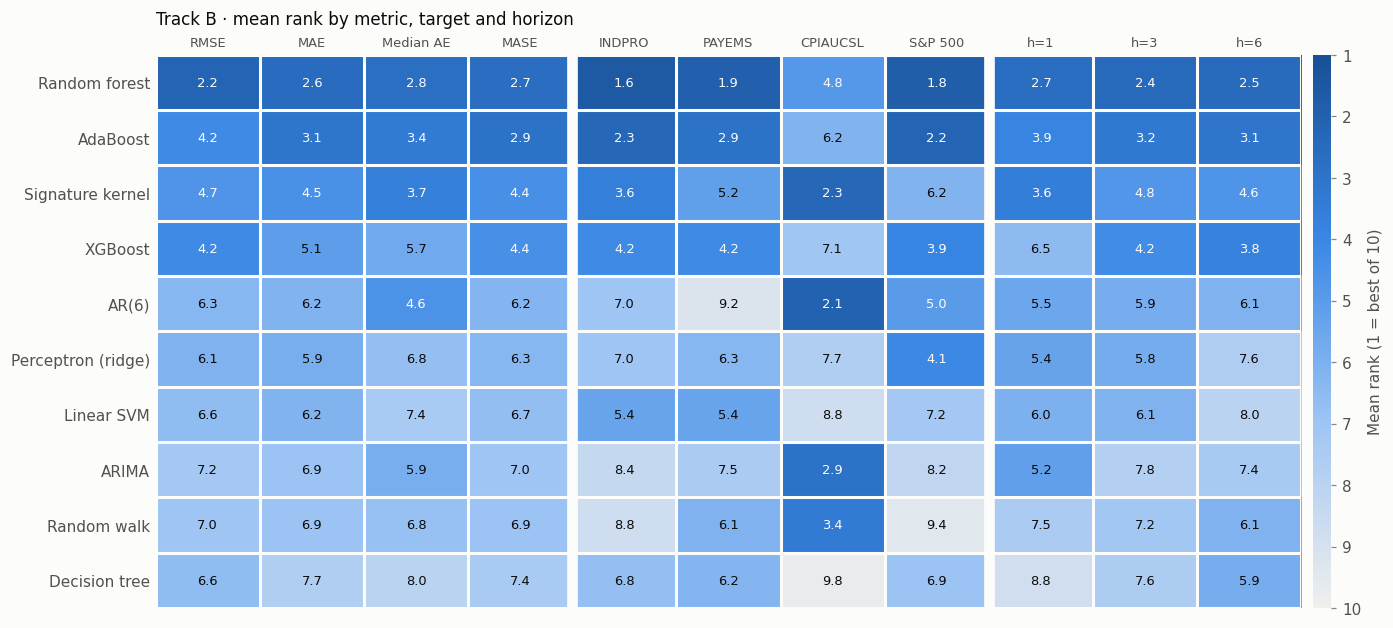

In [7]:
dim_table, groups = by_dimension(main_ranks, ORDER)
save_table(dim_table, f"by_dimension_{MAIN_TRACK}")
rank_heatmap(dim_table, f"Track {MAIN_TRACK} · mean rank by metric, target and horizon", N_MAIN,
             f"by_dimension_{MAIN_TRACK}", groups=groups)

### 2.3 Mean rank by target and horizon

Averaged over the four metrics.

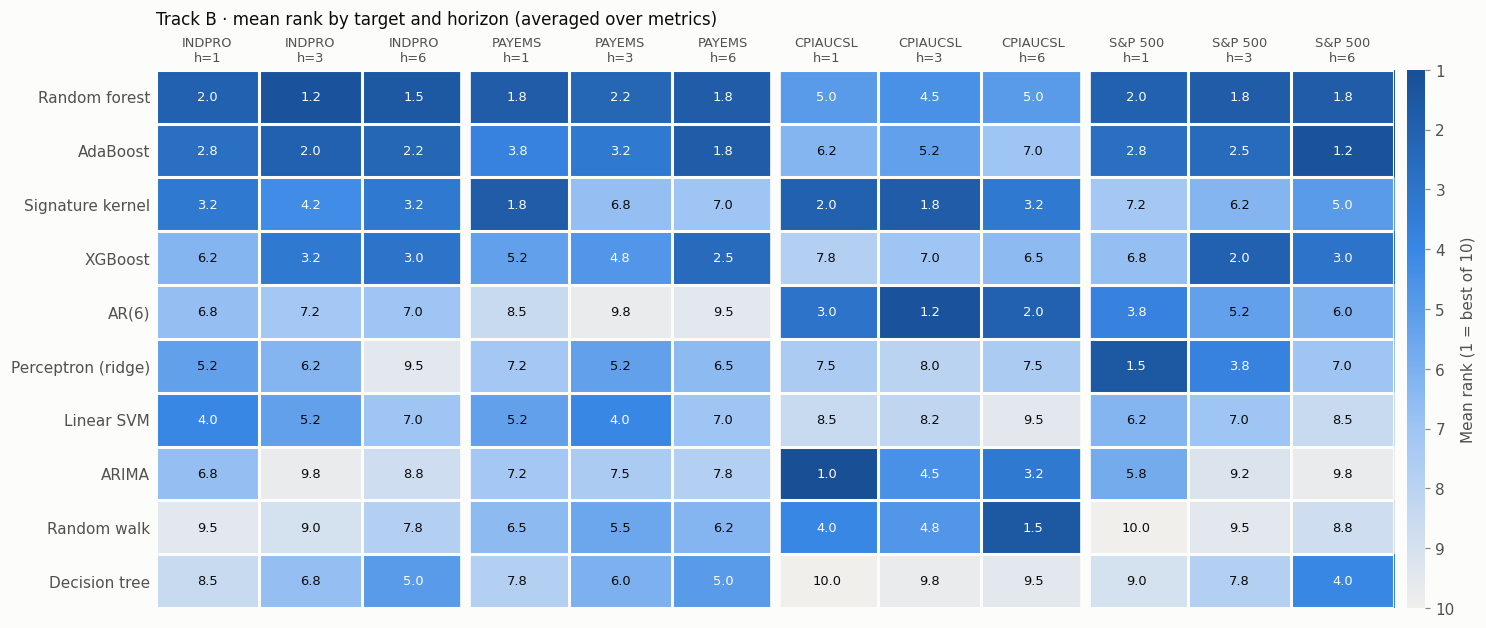

In [8]:
th_table = mean_rank(main_ranks, ["target", "horizon"], ORDER,
                     pd.MultiIndex.from_product([TARGETS, HORIZONS], names=["target", "horizon"]))
save_table(th_table, f"by_target_horizon_{MAIN_TRACK}")
rank_heatmap(th_table, f"Track {MAIN_TRACK} · mean rank by target and horizon (averaged over metrics)", N_MAIN,
             f"by_target_horizon_{MAIN_TRACK}", groups=[len(HORIZONS)] * len(TARGETS))

### 2.4 Rank spread

Every cell's rank as a dot, coloured by target, with the mean rank as a black bar. A tight cluster is a consistent model; dots spread across the axis, or split by colour, is a specialist.

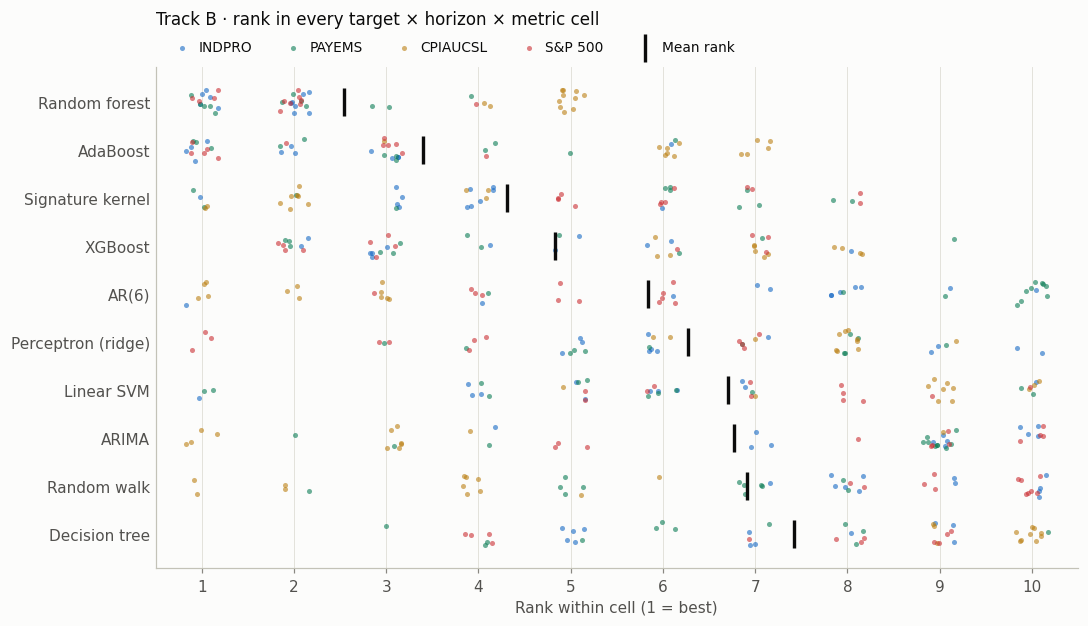

In [9]:
rank_spread(main_ranks, ORDER, f"Track {MAIN_TRACK} · rank in every target × horizon × metric cell", f"spread_{MAIN_TRACK}")

## 3. Recessions, expansions and COVID

The same ranking, recomputed separately over test months in three non-overlapping regimes:

- Expansion: NBER `USREC = 0`, outside the COVID window
- Recession: `USREC = 1`, outside the COVID window (1973–75, 1980, 1981–82, 1990–91, 2001, 2008–09)
- COVID: test months in `COVID_WINDOW`, kept apart because its errors are large enough to swamp the other recessions

Recession and COVID cells rest on far fewer months than expansion cells (counts below), so read them as indicative.

In [10]:
REG_CELL = ["regime", "target", "horizon"]
reg_metrics = cell_metrics(main_runs, REG_CELL)
reg_ranks = rank_cells(reg_metrics, REG_CELL)
check_ranks(reg_ranks, REG_CELL)

months = (main_runs.groupby(["regime", "horizon"])["test_start"].nunique()
          .unstack("horizon").reindex(REGIMES).rename(columns=lambda h: f"h={h}"))
months.index.name = "test months"
months

horizon,h=1,h=3,h=6
test months,,,
Expansion,558,556,553
Recession,72,72,72
COVID,16,16,16


### 3.1 Mean rank by regime

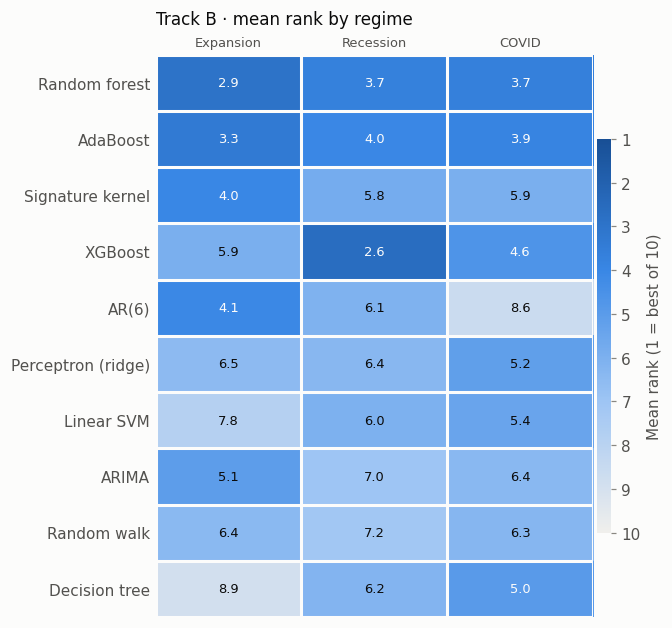

In [11]:
reg_table = mean_rank(reg_ranks, ["regime"], ORDER, REGIMES)
save_table(reg_table, f"by_regime_{MAIN_TRACK}")
rank_heatmap(reg_table, f"Track {MAIN_TRACK} · mean rank by regime", N_MAIN, f"by_regime_{MAIN_TRACK}")

### 3.2 Mean rank by regime and target

Averaged over horizons and metrics.

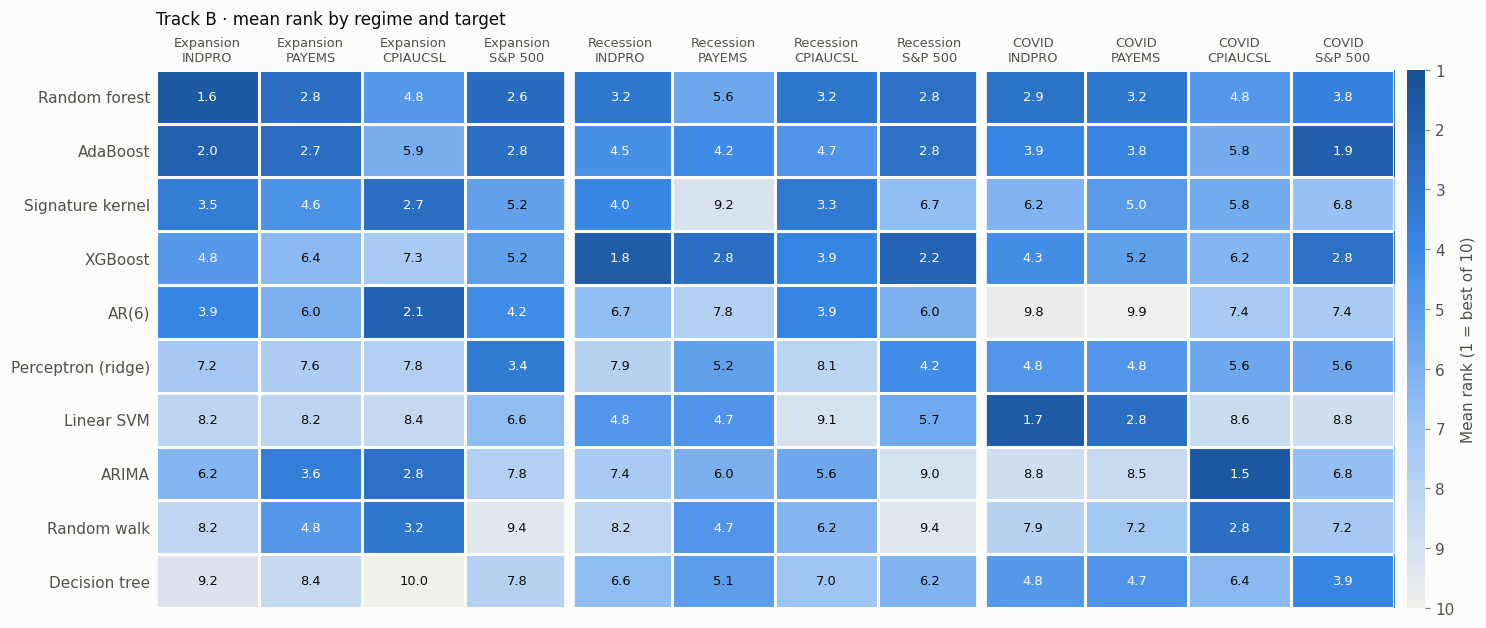

In [12]:
rt_table = mean_rank(reg_ranks, ["regime", "target"], ORDER,
                     pd.MultiIndex.from_product([REGIMES, TARGETS], names=["regime", "target"]))
save_table(rt_table, f"by_regime_target_{MAIN_TRACK}")
rank_heatmap(rt_table, f"Track {MAIN_TRACK} · mean rank by regime and target", N_MAIN,
             f"by_regime_target_{MAIN_TRACK}", groups=[len(TARGETS)] * len(REGIMES))

### 3.3 Rank shift in a crisis

Mean rank in each crisis regime minus mean rank in expansion. Negative = the model moves up the ranking when conditions turn; positive = it falls back.

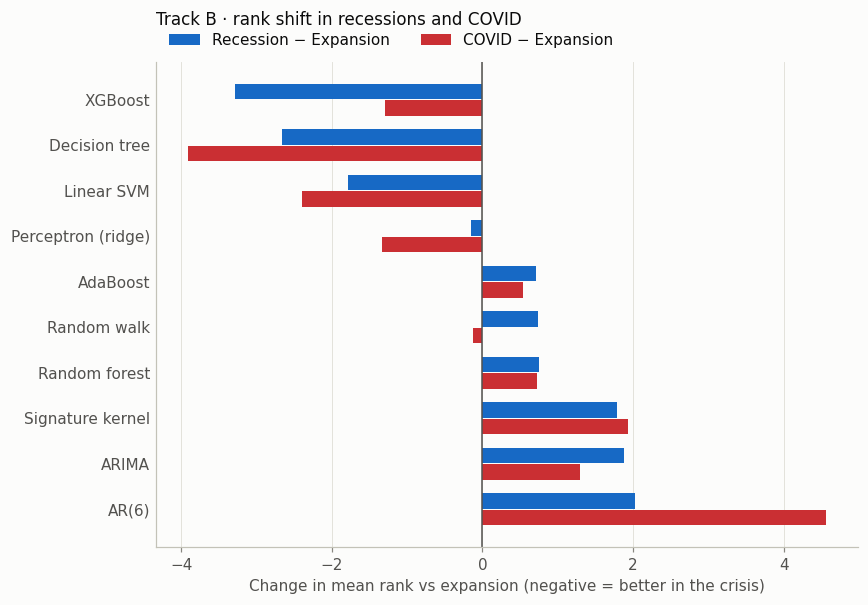

,Recession − Expansion,COVID − Expansion
entry,,
XGBoost,-3.29,-1.29
Decision tree,-2.67,-3.92
Linear SVM,-1.79,-2.40
Perceptron (ridge),-0.15,-1.33
AdaBoost,0.71,0.54
Random walk,0.74,-0.12
Random forest,0.75,0.73
Signature kernel,1.79,1.94
ARIMA,1.89,1.29


In [13]:
shift = reg_table[["Recession", "COVID"]].sub(reg_table["Expansion"], axis=0)
shift.columns = [f"{c} − Expansion" for c in shift.columns]
shift = shift.sort_values(shift.columns[0])
save_table(shift, f"regime_shift_{MAIN_TRACK}")

fig, ax = plt.subplots(figsize=(8, 0.42 * len(shift) + 1.4))
y = np.arange(len(shift))
for k, (col, color) in enumerate(zip(shift.columns, ["#1769c5", "#ca2f33"])):
    ax.barh(y + (k - 0.5) * 0.36, shift[col], height=0.34, color=color, label=col)
ax.axvline(0, color=INK_2, linewidth=1)
ax.set_yticks(y, [entry_label(e) for e in shift.index])
ax.invert_yaxis()
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.set_xlabel("Change in mean rank vs expansion (negative = better in the crisis)")
ax.set_title(f"Track {MAIN_TRACK} · rank shift in recessions and COVID", loc="left", pad=24)
ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2)
fig.tight_layout()
save(fig, f"regime_shift_{MAIN_TRACK}")
plt.show()
shift.rename(index=entry_label).round(2)

### Findings: regimes

Results as of the current run. Recession cells rest on 72 test months and COVID cells on 16, so treat these as indicative.

- Random forest and AdaBoost stay in the top group in every regime. Their lead is largest in expansions and narrows in crises.
- XGBoost moves up the most in recessions (−3.3 places). It is first or second for INDPRO, PAYEMS and S&P 500 in recession months, against a mid-table rank in expansions.
- Decision tree and linear SVM are weak in normal times but move up in COVID (−3.9 and −2.4 places). Linear SVM is the best model for INDPRO in COVID months (mean rank 1.7).
- AR(6) shows the opposite pattern. It ranks well in expansions, especially for CPI, but falls 4.6 places in COVID, where it is near last for INDPRO and PAYEMS: a linear autoregression extrapolates the shock. ARIMA and the signature kernel also lose ground in crises.

## 4. Model profiles

Each model on `MAIN_TRACK` gets one or more labels from simple rules over the tables above. With `n` entries, the top third means a mean rank of at most 1 + (n − 1)/3, and the shift thresholds are shares of the rank range n − 1, so the same rules work for 10 models or 19 configurations:

- Consistently strong: mean rank in the top third and rank SD at or below the median SD
- Consistently weak: mean rank in the bottom third and rank SD at or below the median SD
- Target or horizon specialist: top third on average for at least one target (or horizon) and in the bottom half for another
- Metric-sensitive: mean RMSE rank differs from the mean MAE / median AE rank by at least `METRIC_SHIFT` × (n − 1). Worse on RMSE means occasional large misses
- Regime specialist: mean rank moves by at least `REGIME_SHIFT` × (n − 1) places between expansion and recession or COVID
- Middle of the pack: none of the above

In [14]:
prof_main = profile(main_ranks, reg_ranks)
save_table(prof_main, f"profiles_{MAIN_TRACK}")
summarize_profiles(prof_main)
prof_main.rename(index=entry_label)

Consistently strong
  Random forest                  mean rank  2.54   
  AdaBoost                       mean rank  3.40   strong on S&P 500 (2.2), weak on CPIAUCSL (6.2)

Target specialist
  AdaBoost                       mean rank  3.40   strong on S&P 500 (2.2), weak on CPIAUCSL (6.2)
  Signature kernel               mean rank  4.31   strong on CPIAUCSL (2.3), weak on S&P 500 (6.2)
  XGBoost                        mean rank  4.83   strong on S&P 500 (3.9), weak on CPIAUCSL (7.1); strong on h=6 (3.8), weak on h=1 (6.5); better in Recession (-3.3 places vs expansion)
  AR(6)                          mean rank  5.83   strong on CPIAUCSL (2.1), weak on PAYEMS (9.2); worse in COVID (+4.6 places vs expansion)
  ARIMA                          mean rank  6.77   strong on CPIAUCSL (2.9), weak on INDPRO (8.4)
  Random walk                    mean rank  6.92   strong on CPIAUCSL (3.4), weak on S&P 500 (9.4)

Horizon specialist
  XGBoost                        mean rank  4.83   strong on S&P 50

,mean_rank,rank_sd,profile,notes
entry,,,,
Random forest,2.54,1.52,Consistently strong,
AdaBoost,3.40,2.09,"Consistently strong, Target specialist","strong on S&P 500 (2.2), weak on CPIAUCSL (6.2)"
Signature kernel,4.31,2.17,Target specialist,"strong on CPIAUCSL (2.3), weak on S&P 500 (6.2)"
XGBoost,4.83,2.22,"Target specialist, Horizon specialist, Regime ...","strong on S&P 500 (3.9), weak on CPIAUCSL (7.1..."
AR(6),5.83,3.10,"Target specialist, Regime specialist","strong on CPIAUCSL (2.1), weak on PAYEMS (9.2)..."
Perceptron (ridge),6.27,2.28,Middle of the pack,
Linear SVM,6.71,2.46,Middle of the pack,
ARIMA,6.77,3.14,Target specialist,"strong on CPIAUCSL (2.9), weak on INDPRO (8.4)"
Random walk,6.92,2.73,Target specialist,"strong on CPIAUCSL (3.4), weak on S&P 500 (9.4)"


### Findings: model profiles on Track B

- Consistently strong: random forest is the clear leader. Its mean rank is 2.5, it is in the top 3 in 71% of the 48 cells and never worse than 5th. Its only soft spot is CPI (4.8). AdaBoost is second (mean 3.4, top 3 in 65% of cells), with the same CPI weakness (6.2).
- Specialists by target: CPI has a different winner set from the other three targets. AR(6) (2.1), the signature kernel (2.3), ARIMA (2.9) and even the random walk (3.4) rank at the top for CPIAUCSL, while the tree ensembles fall to the middle. Inflation is persistent, so simple time-series structure beats the curated predictors. The signature kernel is the strongest feature-based model on CPI but weak on S&P 500 (6.2). AR(6) is last on PAYEMS (9.2).
- Specialists by horizon: XGBoost gets better as the horizon grows (6.5 at h=1, 3.8 at h=6).
- Metric sensitivity is small on Track B: rankings under RMSE, MAE, median AE and MASE broadly agree. AdaBoost ranks about one place worse on RMSE than on MAE, a hint of occasional large misses.
- Middle of the pack: the ridge perceptron and linear SVM (mean rank about 6.3 to 6.7) never stand out on any target or horizon.
- Consistently weak: the single decision tree is last overall (7.4) and last on CPI (9.8). Its relative gain in COVID comes from everything else getting worse.

## 5. Configurations: model@track across all tracks

Each model × track pair is ranked as its own entry, so the effect of the input track (A vs B, quantum reservoir tracks vs B) sits on the same leaderboard as the model choice. Models in `FEATURELESS` score the same on every track and appear once. Only pairs that have results are ranked; fold matching is across all entries in each cell.

In [15]:
cfg_runs = ok[~ok["model"].isin(FEATURELESS) | (ok["track"] == MAIN_TRACK)].copy()
cfg_runs["entry"] = np.where(cfg_runs["model"].isin(FEATURELESS), cfg_runs["model"],
                             cfg_runs["model"] + "@" + cfg_runs["track"])

# check the featureless models really are identical across tracks
for m in FEATURELESS:
    d = ok[ok["model"] == m].pivot_table(index=["target", "horizon", "fold_id"], columns="track", values="mse")
    if d.shape[1] > 1:
        print(f"{m}: max spread in fold MSE across {d.shape[1]} tracks = {(d.max(axis=1) - d.min(axis=1)).max():.2e}")

cfg_metrics = cell_metrics(cfg_runs, CELL)
cfg_ranks = rank_cells(cfg_metrics, CELL)
check_ranks(cfg_ranks, CELL)
cfg_ranks["model"] = cfg_ranks["entry"].str.partition("@")[0]
cfg_ranks["track"] = cfg_ranks["entry"].str.partition("@")[2].replace("", MAIN_TRACK)
N_CFG = int(cfg_ranks["n"].max())

cfg_reg_metrics = cell_metrics(cfg_runs, REG_CELL)
cfg_reg_ranks = rank_cells(cfg_reg_metrics, REG_CELL)

lb_cfg = leaderboard(cfg_ranks)
CFG_ORDER = list(lb_cfg.index)
save_table(lb_cfg, "leaderboard_configurations")
print(f"{N_CFG} configurations")
lb_cfg.rename(index=entry_label).round(2)

random_walk: max spread in fold MSE across 6 tracks = 0.00e+00
AR6: max spread in fold MSE across 6 tracks = 0.00e+00


19 configurations


,mean_rank,median_rank,rank_sd,best,worst,top3_share,cells
entry,,,,,,,
Random forest · A,2.60,3.0,1.30,1.0,6.0,0.81,48
AdaBoost · A,3.52,2.0,3.23,1.0,14.0,0.69,48
XGBoost · A,4.29,3.0,3.79,1.0,14.0,0.60,48
Random forest · B,5.46,5.0,2.35,1.0,9.0,0.17,48
AdaBoost · B,6.77,6.0,2.85,2.0,13.0,0.06,48
Signature kernel · B,8.67,8.0,4.40,2.0,16.0,0.15,48
XGBoost · B,8.90,9.5,3.20,4.0,15.0,0.00,48
Perceptron (ridge) · Q_su_pce,9.67,9.0,3.79,1.0,16.0,0.10,48
Perceptron (ridge) · B,11.54,11.5,4.29,1.0,19.0,0.06,48


### 5.1 Mean rank by model and track

The same configuration ranks, laid out with models as rows and tracks as columns. Reading across a row shows how much the input track matters for that model.

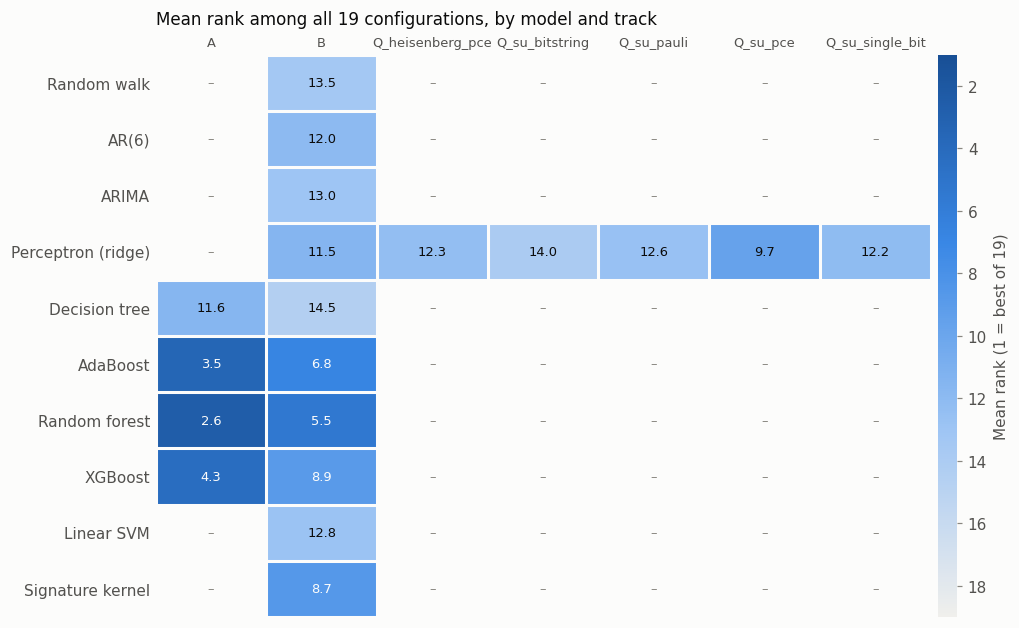

In [16]:
mt_table = (cfg_ranks.groupby(["model", "track"])["rank"].mean().unstack("track")
            .reindex(index=[m for m in MODELS if m in set(cfg_ranks["model"])], columns=TRACKS))
save_table(mt_table, "by_model_track")
rank_heatmap(mt_table, f"Mean rank among all {N_CFG} configurations, by model and track", N_CFG, "by_model_track")

### 5.2 Configurations by metric, target, horizon and regime

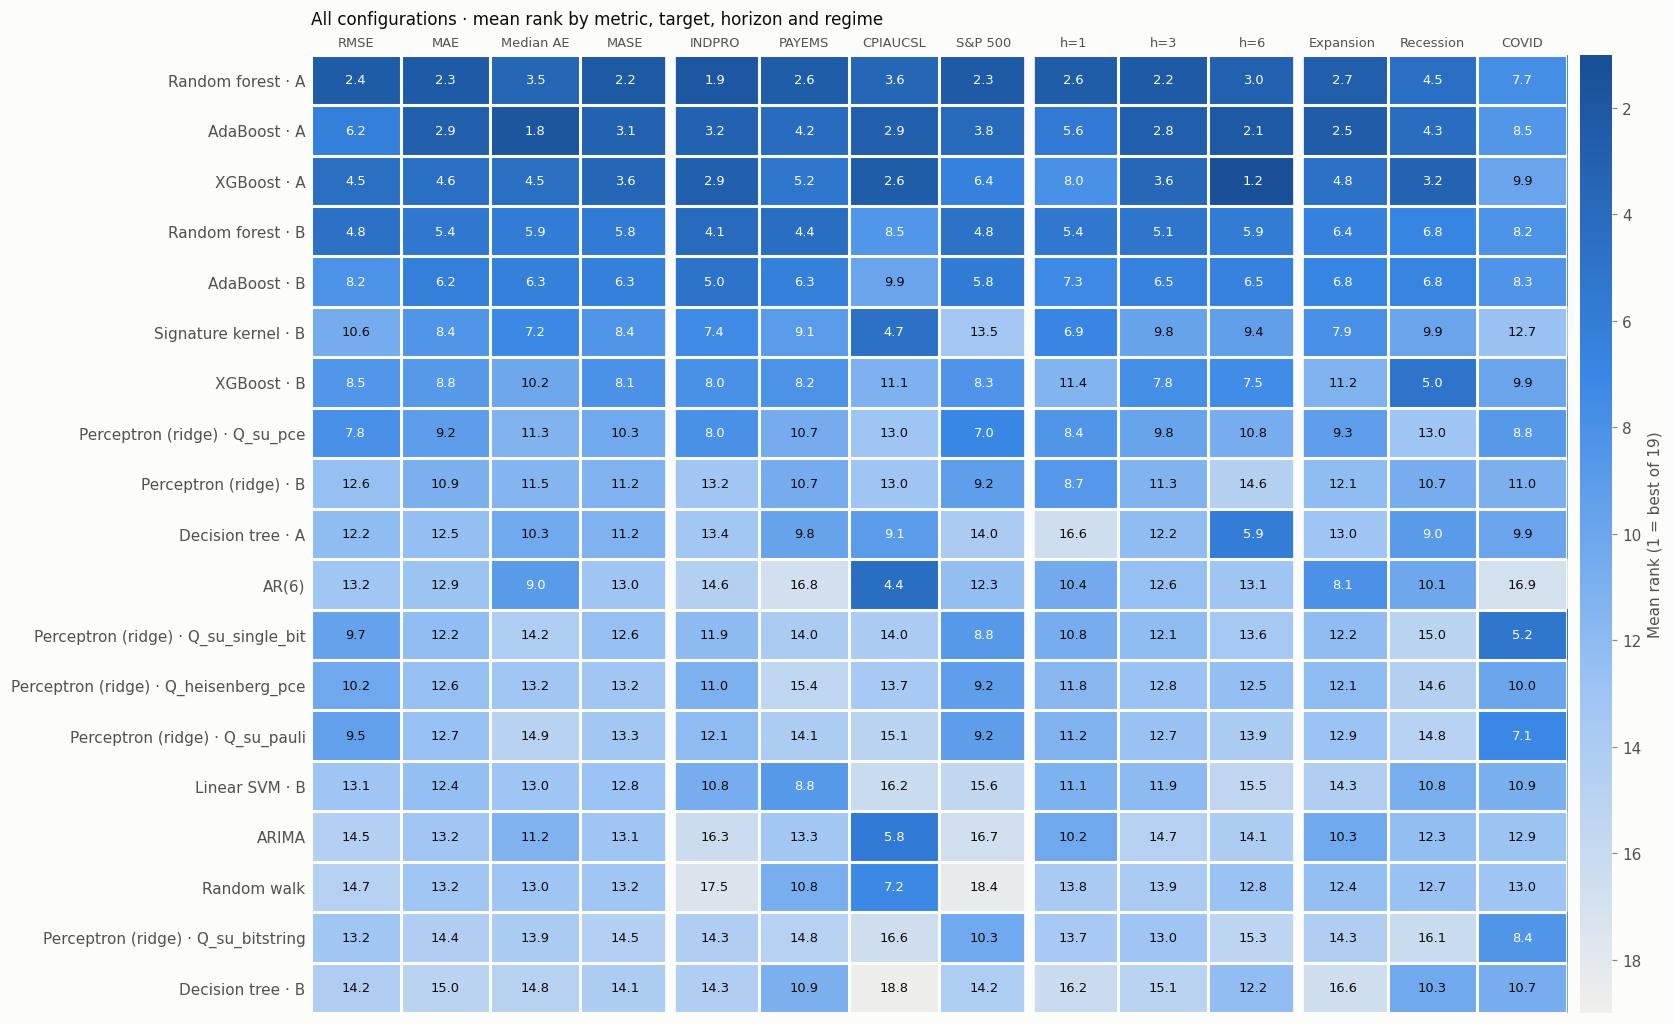

In [17]:
cfg_dim, cfg_groups = by_dimension(cfg_ranks, CFG_ORDER)
cfg_reg = mean_rank(cfg_reg_ranks, ["regime"], CFG_ORDER, REGIMES)
cfg_all = pd.concat([cfg_dim, cfg_reg], axis=1)
save_table(cfg_all, "by_dimension_configurations")
rank_heatmap(cfg_all, "All configurations · mean rank by metric, target, horizon and regime", N_CFG,
             "by_dimension_configurations", groups=[*cfg_groups, len(REGIMES)])

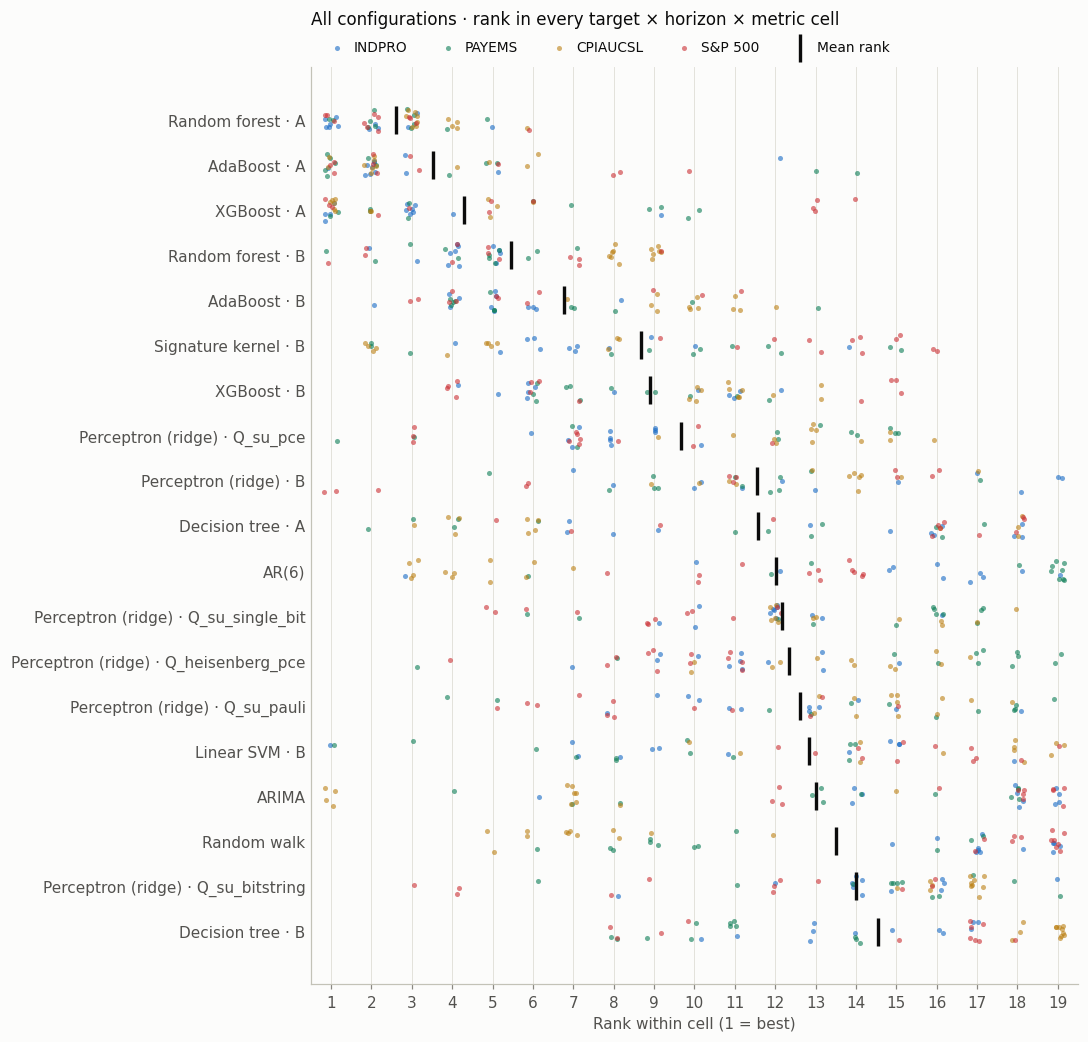

In [18]:
rank_spread(cfg_ranks, CFG_ORDER, "All configurations · rank in every target × horizon × metric cell", "spread_configurations")

### 5.3 Configuration profiles

The rules from section 4, applied to the configuration ranking.

In [19]:
prof_cfg = profile(cfg_ranks, cfg_reg_ranks)
save_table(prof_cfg, "profiles_configurations")
summarize_profiles(prof_cfg)
prof_cfg.rename(index=entry_label)

Consistently strong
  Random forest · A              mean rank  2.60   
  AdaBoost · A                   mean rank  3.52   RMSE rank +3.9 vs MAE/median AE: occasional large misses; worse in COVID (+6.0 places vs expansion)
  XGBoost · A                    mean rank  4.29   
  Random forest · B              mean rank  5.46   
  AdaBoost · B                   mean rank  6.77   

Target specialist
  Signature kernel · B           mean rank  8.67   strong on CPIAUCSL (4.7), weak on S&P 500 (13.5)
  Perceptron (ridge) · Q_su_pce  mean rank  9.67   strong on S&P 500 (7.0), weak on CPIAUCSL (13.0)
  AR(6)                          mean rank 12.02   strong on CPIAUCSL (4.4), weak on PAYEMS (16.8); worse in COVID (+8.8 places vs expansion)
  ARIMA                          mean rank 13.02   strong on CPIAUCSL (5.8), weak on S&P 500 (16.7)

Horizon specialist
  Decision tree · A              mean rank 11.56   strong on h=6 (5.9), weak on h=1 (16.6)

Regime specialist
  AdaBoost · A                

,mean_rank,rank_sd,profile,notes
entry,,,,
Random forest · A,2.60,1.30,Consistently strong,
AdaBoost · A,3.52,3.23,"Consistently strong, Metric-sensitive, Regime ...",RMSE rank +3.9 vs MAE/median AE: occasional la...
XGBoost · A,4.29,3.79,Consistently strong,
Random forest · B,5.46,2.35,Consistently strong,
AdaBoost · B,6.77,2.85,Consistently strong,
Signature kernel · B,8.67,4.40,Target specialist,"strong on CPIAUCSL (4.7), weak on S&P 500 (13.5)"
XGBoost · B,8.90,3.20,Regime specialist,better in Recession (-6.2 places vs expansion)
Perceptron (ridge) · Q_su_pce,9.67,3.79,Target specialist,"strong on S&P 500 (7.0), weak on CPIAUCSL (13.0)"
Perceptron (ridge) · B,11.54,4.29,Middle of the pack,


### Findings: configurations across tracks

- Track A (full 123-variable panel) beats Track B (curated) for every tree model. Random forest@A (2.6), AdaBoost@A (3.5) and XGBoost@A (4.3) take the top three spots, ahead of their own Track B versions (5.5, 6.8, 8.9). The decision tree also improves (11.6 vs 14.5).
- The A-track ensembles are the configurations that lose the most ground in COVID (5 to 6 places for random forest, AdaBoost and XGBoost on A). AdaBoost@A is also metric-sensitive: it ranks 3.9 places worse on RMSE than on MAE, so it wins the typical month but has some large misses.
- Quantum tracks, all fed to the ridge perceptron: Q_su_pce is the only one that beats the perceptron on Track B (9.7 vs 11.5). It is the best non-tree configuration on S&P 500. The other four quantum tracks rank below the Track B perceptron (12.2 to 14.0), and Q_su_bitstring is second to last overall.
- The quantum tracks share a pattern: they rank better on RMSE than on MAE or median AE, and better in COVID than in expansions (Q_su_single_bit moves up 7 places, to 5.2 in COVID). The reservoir features seem to damp the large misses but add noise in ordinary months. With only 16 COVID months, this is worth checking rather than claiming.
- No quantum configuration comes near the tree ensembles. The best quantum entry (Q_su_pce) ranks 8th of 19.